# RehaPiano – porovnanie testov EXACT_FORCE a rytmus

**Zadanie (6. týždeň):** *Spracovať dokumentáciu do textovej formy, kde budú výsledky interpretované. Urobiť diskusiu
podľa aktuálnych dát. Vylepšiť analýzu podľa svojho uváženia – aspoň porovnať oproti sebe závery z dát na exact force
a rythm test.*

Tento notebook je **vylepšenie analýzy**: porovnáva závery oboch testov. Vychádza z výsledkov 5. týždňa
(`notebooks/exact_force/statisticka_analyza_exact_force.ipynb` – D. Sholtys, `notebooks/rhythm/statisticka_analyza_rytmus.ipynb`
– M. Kuznietsov) a pridáva nové analýzy, ktoré sa dajú urobiť len s oboma testami naraz.

**Dva testy:**
- **EXACT_FORCE** – osoba drží všetkými prstami rovnomernú silu (4 pokusy po 16 s): meria **tras a stabilitu sily**.
- **RYTMUS** – osoba čo najrýchlejšie rytmicky stláča obomi rukami naraz (4 pokusy po 31 s, 1. pokus je nácvik):
  meria **rýchlosť, koordináciu a rovnováhu rúk**.

**Dáta:** tí istí ľudia v oboch testoch – 76 zdravých bez ťažkostí podľa dotazníka a 48 pacientov.

**Otázky:**
1. Aké sú závery oboch testov vedľa seba?
2. Ktoré rozdiely medzi zdravými a pacientmi zostávajú, keď porovnáme **rovnako starých** ľudí – rovnakou metódou v oboch testoch?
3. Ukazujú oba testy slabšiu ruku rovnako?
4. Merajú oba testy to isté?
5. Rozpoznávajú klasifikátory oboch testov tých istých pacientov? Pomôže ich spojenie?
6. Ktorý test dáva **stabilnejšie výsledky** pri opakovanom meraní (pacienti merali dvakrát)?

Kód: `src/rehapiano/comparison.py`, skript `scripts/run_comparison.py` (tabuľky v `outputs/comparison/`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

# ROOT = repository root (package src/rehapiano, outputs/)
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "rehapiano").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from rehapiano.common.config import COMBINED_OUTPUT_DIR, COMPARISON_OUTPUT_DIR
from rehapiano.exact_force import parameters as ep
from rehapiano.exact_force.config import ANALYSIS_OUTPUT_DIR as EF_OUT
from rehapiano.rhythm import parameters as rp
from rehapiano.rhythm.config import ANALYSIS_OUTPUT_DIR as RH_OUT, HAND_BALANCE_OUTPUT_DIR

read = lambda folder: {path.stem: pd.read_csv(path) for path in sorted(folder.glob("*.csv"))}
C, EF, RH, COMB = read(COMPARISON_OUTPUT_DIR), read(EF_OUT), read(RH_OUT), read(COMBINED_OUTPUT_DIR)
TESTS = {"EXACT_FORCE": EF, "RYTMUS": RH}
PARAMETERS = {"EXACT_FORCE": ep.PARAMETERS, "RYTMUS": rp.PARAMETERS}
FIG = Path.cwd() / "figures" / "porovnanie_exact_force_rytmus"; FIG.mkdir(parents=True, exist_ok=True)

NAME = {
    # EXACT_FORCE (names as in D. Sholtys' notebook)
    "tremor_amplitude": "amplitúda trasu", "tremor_amplitude_worse_hand": "amplitúda trasu horšej ruky",
    "movement_amplitude": "pomalé korekcie sily", "tremor_to_movement": "podiel trasu (4–15 / 0–4 Hz)",
    "tremor_frequency_hz": "frekvencia trasu", "tremor_prominence": "rytmickosť trasu", "mean_force": "sila prstov",
    "force_balance": "rovnováha síl rúk", "tremor_balance": "rovnováha trasu rúk", "finger_spread": "rozdiely medzi prstami",
    # RHYTHM
    "press_rate_hz": "tempo", "interval_cv": "nepravidelnosť rytmu", "amplitude_strong": "sila silnejšej ruky",
    "amplitude_weak": "sila slabšej ruky", "balance": "rovnováha rúk", "amplitude_cv": "nestálosť sily",
    "sync_lag_ms": "oneskorenie medzi rukami", "release_ratio": "neúplné uvoľnenie",
    "fatigue_amplitude": "únava – sila", "fatigue_rate": "únava – tempo"}

TEST_COLORS = {"EXACT_FORCE": "#7f56c2", "RYTMUS": "#eb6834"}
GROUP_COLORS = {"control": "#2a78d6", "patient": "#eb6834"}
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "axes.titleweight": "bold", "axes.titlesize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10,
})
SK_GROUP = {"control": "zdraví", "patient": "pacienti"}


def fmt(value, digits=2):
    # Slovak decimal comma
    return f"{value:.{digits}f}".replace(".", ",")


def pval(p):
    return "< 0,001" if p < 0.001 else fmt(p, 3)


def names(parameters):
    return ", ".join(NAME[p] for p in parameters) or "žiadny"


def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()


diff = C["group_differences"].set_index("parameter")
n_h, n_p = int(diff["n_controls"].max()), int(diff["n_patients"].max())
print(f"zdraví: {n_h}, pacienti: {n_p} (tí istí ľudia v oboch testoch)")

zdraví: 76, pacienti: 48 (tí istí ľudia v oboch testoch)


## 1. Závery oboch testov vedľa seba

Tabuľka zhŕňa výsledky 5. týždňa (štyri časti zadania) pre oba testy. Riadok *pri rovnakom veku* a *opakovateľnosť*
sú nové (časti 2 a 6 tohto notebooku).

In [2]:
def summary(test):
    t, d = TESTS[test], diff.loc[diff["test"] == test]
    h = t["hypotheses"].set_index("parameter")
    same_age = d.loc[(d["p_same_age_holm"] < 0.05) & d["as_expected"]].index
    opposite = d.loc[(d["p_same_age_holm"] < 0.05) & ~d["as_expected"]].index
    strongest = d["separation"].idxmax()
    ages = t["age_trends"]
    outside = t["outside_norms"].assign(total=lambda f: f["below"] + f["above"]).set_index("parameter")["total"]
    clf = t["classifier"].loc[t["classifier"]["main"] & (t["classifier"]["model"] == "logistická regresia")]
    auc = lambda features, older=False: clf.loc[(clf["features"] == features)
                                                & (clf["set"].str.contains("≥ 50") == older), "auc"].iloc[0]
    params = clf["features"].iloc[0]
    abl = t["ablation_parameters"]
    rep = C["repeatability"].loc[C["repeatability"]["test"] == test]
    return {
        "čo test meria": "tras a stabilita držanej sily" if test == "EXACT_FORCE" else "rýchlosť, koordinácia a rovnováha rúk",
        "1. rozdiel zdraví – pacienti (všetci, Holm p < 0,05)": f"{int((h['p_holm'] < 0.05).sum())} z 10",
        "1. rozdiel pri rovnakom veku, v očakávanom smere": f"{len(same_age)} z 10: {names(same_age)}",
        "1. pri rovnakom veku, ale opačný smer": names(opposite),
        "1. najväčší rozdiel (AUC)": f"{NAME[strongest]} ({fmt(d.loc[strongest, 'separation'])})",
        "2. mení sa s vekom u zdravých (Holm)": names(ages.loc[ages["age_dependent"], "parameter"]),
        "2. najčastejšie mimo normy": f"{NAME[outside.idxmax()]} ({outside.max()} z {n_p} pacientov)",
        "3. klasifikátor – AUC (parametre testu)": fmt(auc(params)),
        "3. klasifikátor – AUC (+ vek)": fmt(auc(params + " + vek")),
        "3. klasifikátor – AUC (len ≥ 50 rokov)": fmt(auc(params, older=True)),
        "4. ablácia – najsilnejší faktor sám": f"{abl.loc[abl['auc_alone'].idxmax(), 'group']} ({fmt(abl['auc_alone'].max())})",
        "4. ablácia – najväčší pokles bez faktora": f"{abl.loc[abl['auc_drop'].idxmax(), 'group']} ({fmt(abl['auc_drop'].max(), 3)})",
        "6. opakovateľnosť – medián ICC parametrov": fmt(rep["icc"].median()),
    }


overview = pd.DataFrame({test: summary(test) for test in TESTS})
overview.index.name = "otázka"
display(overview.style.set_properties(**{"text-align": "left"}))

,EXACT_FORCE,RYTMUS
otázka,,
čo test meria,tras a stabilita držanej sily,"rýchlosť, koordinácia a rovnováha rúk"
"1. rozdiel zdraví – pacienti (všetci, Holm p < 0,05)",8 z 10,5 z 10
"1. rozdiel pri rovnakom veku, v očakávanom smere","4 z 10: amplitúda trasu, amplitúda trasu horšej ruky, pomalé korekcie sily, rozdiely medzi prstami","3 z 10: tempo, rovnováha rúk, oneskorenie medzi rukami"
"1. pri rovnakom veku, ale opačný smer",žiadny,sila silnejšej ruky
1. najväčší rozdiel (AUC),"pomalé korekcie sily (0,89)","tempo (0,80)"
2. mení sa s vekom u zdravých (Holm),podiel trasu (4–15 / 0–4 Hz),žiadny
2. najčastejšie mimo normy,pomalé korekcie sily (11 z 48 pacientov),rovnováha rúk (19 z 48 pacientov)
3. klasifikátor – AUC (parametre testu),"0,85","0,85"
3. klasifikátor – AUC (+ vek),"0,89","0,90"


In [3]:
d = diff
both = COMB["classifier"]
both_auc = both.loc[(both["model"] == "logistická regresia") & (both["features"] == "EXACT_FORCE + rytmus")
                    & ~both["set"].str.contains("≥ 50"), "auc"].iloc[0]
display(Markdown(f"""
**Záver 1:** oba testy oddelia pacientov **rovnako dobre** (AUC klasifikátora ~0,85), ale **každý iným spôsobom**:
- **EXACT_FORCE** zachytí, že pacientom **viac kolíše držaná sila** a viac sa im **trasú prsty**;
- **rytmus** zachytí, že pacienti **stláčajú pomalšie**, jedna ruka **tlačí slabšie** a **zaostáva** za druhou.

Žiadny parameter sa u zdravých po Holmovej korekcii nemení s vekom v rytme; v EXACT_FORCE len podiel trasu.
Oba testy spolu dávajú AUC {fmt(both_auc)} (notebook `klasifikator_oba_testy.ipynb`).
"""))


**Záver 1:** oba testy oddelia pacientov **rovnako dobre** (AUC klasifikátora ~0,85), ale **každý iným spôsobom**:
- **EXACT_FORCE** zachytí, že pacientom **viac kolíše držaná sila** a viac sa im **trasú prsty**;
- **rytmus** zachytí, že pacienti **stláčajú pomalšie**, jedna ruka **tlačí slabšie** a **zaostáva** za druhou.

Žiadny parameter sa u zdravých po Holmovej korekcii nemení s vekom v rytme; v EXACT_FORCE len podiel trasu.
Oba testy spolu dávajú AUC 0,88 (notebook `klasifikator_oba_testy.ipynb`).


## 2. Rozdiely zdraví – pacienti rovnakou metódou v oboch testoch

V 5. týždni sme použili v každom teste trochu iné kontroly veku. Tu použijeme **jednu metódu pre všetkých 20 parametrov**:
- **pri rovnakom veku:** pacientov porovnáme len so zdravými **v tej istej dekáde** (Mann-Whitney v každej dekáde,
  spojený do jedného testu – **van Elterenov test**), p-hodnoty opravené Holmovou metódou v každom teste;
- **veľkosť rozdielu:** AUC (0,5 = žiadny rozdiel, 1 = úplné oddelenie). Smer neberieme do úvahy – AUC 0,20 (pacienti nižší)
  je rovnako silné ako 0,80 (pacienti vyšší), preto na grafe ukazujeme **max(AUC, 1 − AUC)**.

Plný bod = rozdiel **zostáva aj pri rovnakom veku** (Holm p < 0,05); prázdny = nezostáva. Farba testu = rozdiel
v smere, ktorý sme čakali; **sivá** = opačný smer.

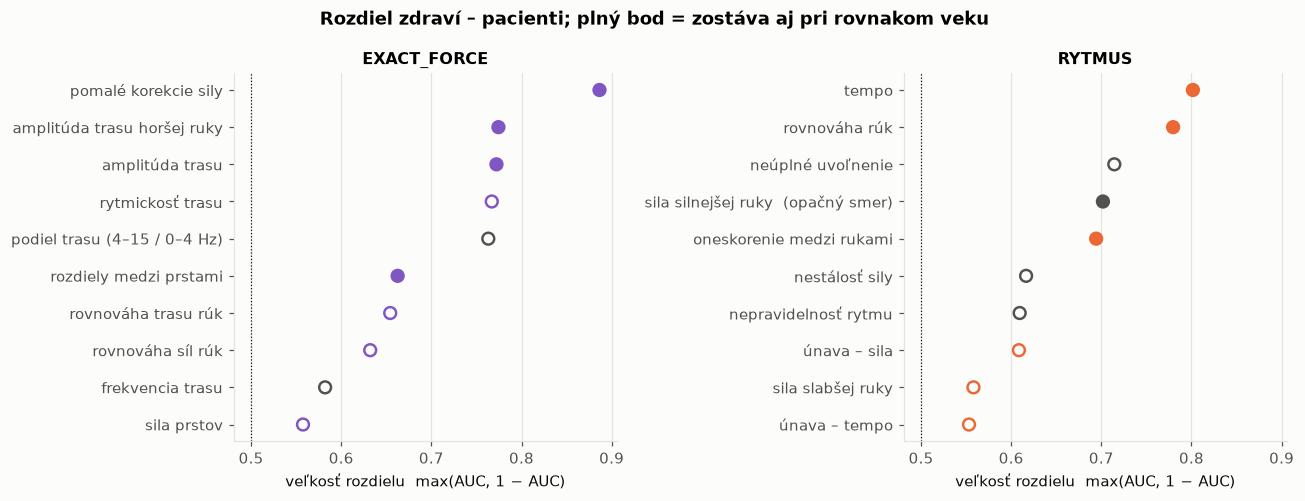

,test,parameter,medián zdraví,medián pacienti,AUC,p pri rovnakom veku (Holm),smer podľa hypotézy
0,EXACT_FORCE,amplitúda trasu,"9,27e-06","1,57e-05","0,77","0,008",áno
1,EXACT_FORCE,amplitúda trasu horšej ruky,"1,03e-05","1,93e-05","0,77","0,001",áno
2,EXACT_FORCE,pomalé korekcie sily,"6,22e-05","0,000171","0,89","< 0,001",áno
3,EXACT_FORCE,podiel trasu (4–15 / 0–4 Hz),"0,161","0,107","0,24","0,109",nie
4,EXACT_FORCE,frekvencia trasu,"5,42","5,29","0,42","0,962",nie
5,EXACT_FORCE,rytmickosť trasu,"2,77","3,46","0,77","0,147",áno
6,EXACT_FORCE,sila prstov,"0,0196","0,0191","0,44","0,962",áno
7,EXACT_FORCE,rovnováha síl rúk,"0,939","0,894","0,37","0,962",áno
8,EXACT_FORCE,rovnováha trasu rúk,"0,817","0,738","0,35","0,962",áno
9,EXACT_FORCE,rozdiely medzi prstami,"0,224","0,317","0,66","0,007",áno


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for ax, test in zip(axes, TESTS):
    t = diff.loc[diff["test"] == test].sort_values("separation")
    y = np.arange(len(t))
    significant = t["p_same_age_holm"] < 0.05
    color = np.where(t["as_expected"], TEST_COLORS[test], MUTED)
    ax.scatter(t["separation"], y, s=60, facecolors=np.where(significant, color, "none"), edgecolors=color, lw=1.6, zorder=3)
    ax.set_yticks(y, [NAME[p] + ("  (opačný smer)" if not e and s else "") for p, e, s in
                      zip(t.index, t["as_expected"], significant)])
    ax.axvline(0.5, color=TEXT, lw=0.8, ls=":")
    ax.set_title(test); ax.set_xlabel("veľkosť rozdielu  max(AUC, 1 − AUC)"); ax.grid(axis="y", visible=False)
fig.suptitle("Rozdiel zdraví – pacienti; plný bod = zostáva aj pri rovnakom veku", fontweight="bold")
save(fig, "01_rozdiely_oba_testy")

display(pd.DataFrame({
    "test": diff["test"], "parameter": diff.index.map(NAME),
    "medián zdraví": diff["median_controls"].map(lambda v: f"{v:.3g}".replace(".", ",")),
    "medián pacienti": diff["median_patients"].map(lambda v: f"{v:.3g}".replace(".", ",")),
    "AUC": diff["auc"].map(fmt), "p pri rovnakom veku (Holm)": diff["p_same_age_holm"].map(pval),
    "smer podľa hypotézy": np.where(diff["as_expected"], "áno", "nie")}).reset_index(drop=True))

In [5]:
ef_d, rh_d = diff.loc[diff["test"] == "EXACT_FORCE"], diff.loc[diff["test"] == "RYTMUS"]
sig = lambda frame: frame.loc[frame["p_same_age_holm"] < 0.05]
display(Markdown(f"""
**Záver 2:**
- Pri rovnakom veku zostáva v **EXACT_FORCE {len(sig(ef_d))}** a v **rytme {len(sig(rh_d))}** parametrov.
  EXACT_FORCE: {names(sig(ef_d).index)}. Rytmus: {names(sig(rh_d).index)}.
- **Najsilnejší parameter celkovo** sú **pomalé korekcie sily** v EXACT_FORCE (AUC {fmt(ef_d.loc['movement_amplitude', 'separation'])}),
  v rytme **tempo** ({fmt(rh_d.loc['press_rate_hz', 'separation'])}) a **rovnováha rúk** ({fmt(rh_d.loc['balance', 'separation'])}).
- **Rovnováha rúk sa správa v testoch rozdielne:** v rytme je u pacientov výrazne nižšia aj pri rovnakom veku
  (p {pval(rh_d.loc['balance', 'p_same_age_holm'])}), v EXACT_FORCE nie (p {pval(ef_d.loc['force_balance', 'p_same_age_holm'])}).
  Pri pokojnom držaní sily stačí slabšej ruke malá sila; pri rýchlom stláčaní sa slabosť jednej ruky ukáže (časť 3).
- **Sila** sa v EXACT_FORCE nelíši (úlohou je držať predpísanú silu), v rytme tlačia pacienti silnejšou rukou **silnejšie** –
  opačne ako sme čakali; súvisí to s pomalším tempom (5. týždeň).
- **Pravidelnosť** (rytmu v rytmickom teste, frekvencia trasu v EXACT_FORCE) sa v žiadnom teste nelíši.
"""))


**Záver 2:**
- Pri rovnakom veku zostáva v **EXACT_FORCE 4** a v **rytme 4** parametrov.
  EXACT_FORCE: amplitúda trasu, amplitúda trasu horšej ruky, pomalé korekcie sily, rozdiely medzi prstami. Rytmus: tempo, sila silnejšej ruky, rovnováha rúk, oneskorenie medzi rukami.
- **Najsilnejší parameter celkovo** sú **pomalé korekcie sily** v EXACT_FORCE (AUC 0,89),
  v rytme **tempo** (0,80) a **rovnováha rúk** (0,78).
- **Rovnováha rúk sa správa v testoch rozdielne:** v rytme je u pacientov výrazne nižšia aj pri rovnakom veku
  (p 0,016), v EXACT_FORCE nie (p 0,962).
  Pri pokojnom držaní sily stačí slabšej ruke malá sila; pri rýchlom stláčaní sa slabosť jednej ruky ukáže (časť 3).
- **Sila** sa v EXACT_FORCE nelíši (úlohou je držať predpísanú silu), v rytme tlačia pacienti silnejšou rukou **silnejšie** –
  opačne ako sme čakali; súvisí to s pomalším tempom (5. týždeň).
- **Pravidelnosť** (rytmu v rytmickom teste, frekvencia trasu v EXACT_FORCE) sa v žiadnom teste nelíši.


## 3. Rovnováha rúk v oboch testoch

Rovnováha rúk = slabšia ruka / silnejšia ruka (1 = rovnaké). V EXACT_FORCE je to priemerná držaná sila rúk, v rytme
veľkosť stlačenia. Je to jediný parameter, ktorý sa dá v oboch testoch porovnať priamo. Čiarkované čiary = dolná hranica
normy zdravých (2,5. percentil) v každom teste.

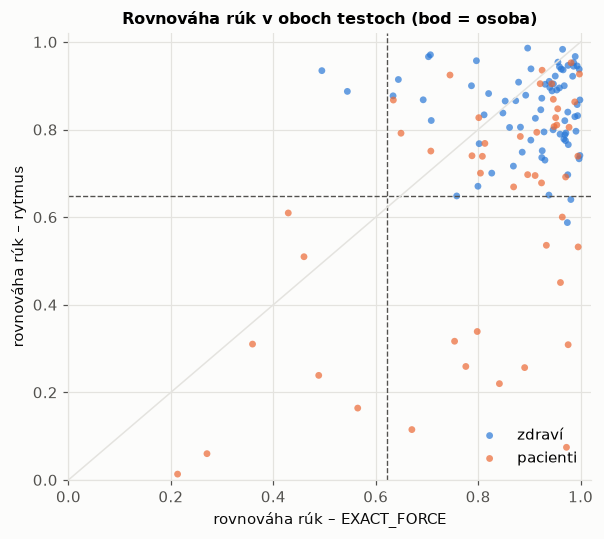

Pacienti pod normou zdravých (riadky EXACT_FORCE, stĺpce rytmus):


pod normou v rytme,False,True
pod normou v EXACT_FORCE,,
False,29,12
True,0,7



**Záver 3:** pod normou zdravých je v rytme **19** pacientov, v EXACT_FORCE len
**7**. Spearmanova korelácia rovnováhy medzi testami je u pacientov
0,39, u zdravých -0,02 – testy teda **nehovoria o rovnováhe to isté**. Keď však oba testy
slabú ruku nájdu, je to v 88 % prípadov **tá istá ruka** (4. týždeň).
Rytmický test je na slabšiu ruku **citlivejší**: rýchle opakované stláčanie ruku viac zaťaží ako pokojné držanie sily.


In [6]:
people = (EF["people"].loc[EF["people"]["screened"], ["patient_id", "group", "age", "force_balance"]]
          .merge(RH["people"][["patient_id", "balance"]], on="patient_id"))
low = {"EXACT_FORCE": EF["norms_by_age_model"].set_index("parameter").loc["force_balance", "q2.5"].iloc[0],
       "RYTMUS": RH["norms_by_age_model"].set_index("parameter").loc["balance", "q2.5"].iloc[0]}
fig, ax = plt.subplots(figsize=(5.6, 5))
for group in ["control", "patient"]:
    g = people.loc[people["group"] == group]
    ax.scatter(g["force_balance"], g["balance"], s=20, color=GROUP_COLORS[group], alpha=0.7, edgecolor="none",
               label=SK_GROUP[group])
ax.axvline(low["EXACT_FORCE"], color=MUTED, lw=0.9, ls="--"); ax.axhline(low["RYTMUS"], color=MUTED, lw=0.9, ls="--")
ax.plot([0, 1], [0, 1], color=GRID, lw=1)
ax.set_xlabel("rovnováha rúk – EXACT_FORCE"); ax.set_ylabel("rovnováha rúk – rytmus")
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02); ax.legend(loc="lower right")
ax.set_title("Rovnováha rúk v oboch testoch (bod = osoba)")
save(fig, "02_rovnovaha_ruk")

patients = people.loc[people["group"] == "patient"]
below = pd.DataFrame({"pod normou v EXACT_FORCE": patients["force_balance"] < low["EXACT_FORCE"],
                      "pod normou v rytme": patients["balance"] < low["RYTMUS"]})
counts = pd.crosstab(below["pod normou v EXACT_FORCE"], below["pod normou v rytme"])
rho = {g: stats.spearmanr(f["force_balance"], f["balance"], nan_policy="omit")[0] for g, f in people.groupby("group")}
week4 = pd.read_csv(HAND_BALANCE_OUTPUT_DIR / "test_agreement.csv").iloc[0]
print("Pacienti pod normou zdravých (riadky EXACT_FORCE, stĺpce rytmus):")
display(counts)
display(Markdown(f"""
**Záver 3:** pod normou zdravých je v rytme **{int(below['pod normou v rytme'].sum())}** pacientov, v EXACT_FORCE len
**{int(below['pod normou v EXACT_FORCE'].sum())}**. Spearmanova korelácia rovnováhy medzi testami je u pacientov
{fmt(rho['patient'])}, u zdravých {fmt(rho['control'])} – testy teda **nehovoria o rovnováhe to isté**. Keď však oba testy
slabú ruku nájdu, je to v {fmt(100 * week4['same_weaker_hand_if_flagged'], 0)} % prípadov **tá istá ruka** (4. týždeň).
Rytmický test je na slabšiu ruku **citlivejší**: rýchle opakované stláčanie ruku viac zaťaží ako pokojné držanie sily.
"""))

## 4. Merajú oba testy to isté?

Pre každú dvojicu parametrov (EXACT_FORCE × rytmus) Spearmanova korelácia – zvlášť **u pacientov** (graf) a u zdravých.
Ak by testy merali to isté, boli by korelácie vysoké (blízko ±1).

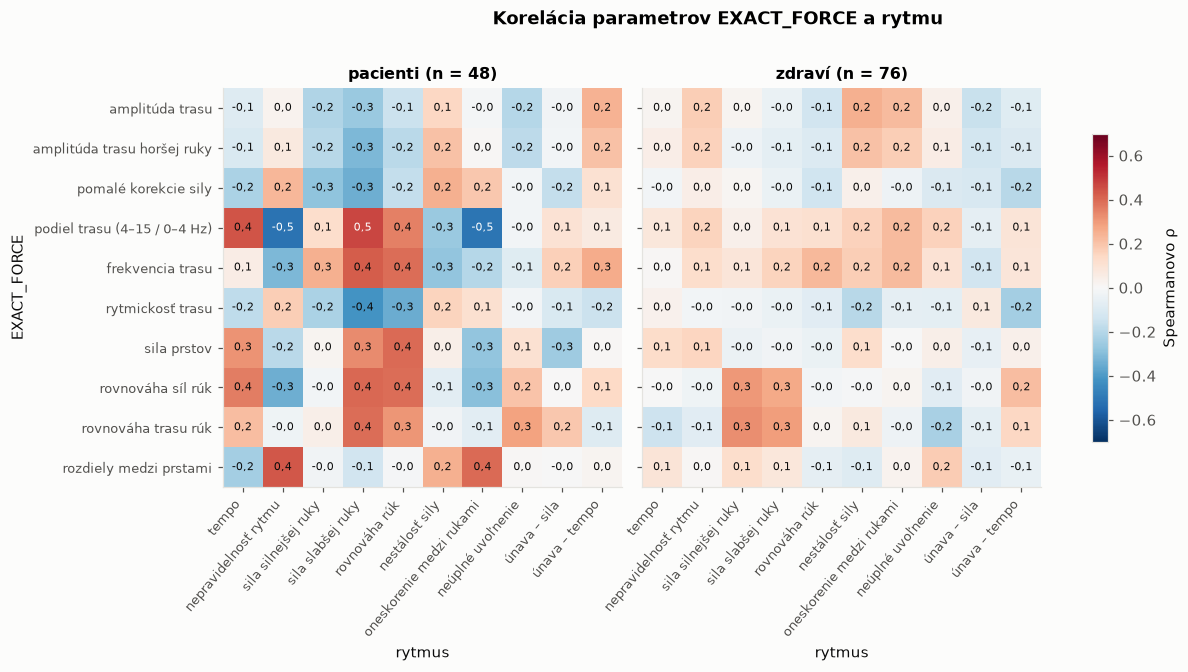


**Záver 4:** u zdravých testy **takmer nesúvisia** (medián |ρ| = 0,08, najviac
0,33). U pacientov sú korelácie **o niečo vyššie** (medián |ρ| = 0,19,
najviac 0,52), napr. podiel trasu (4–15 / 0–4 Hz) × nepravidelnosť rytmu ρ = -0,52; podiel trasu (4–15 / 0–4 Hz) × oneskorenie medzi rukami ρ = -0,51; podiel trasu (4–15 / 0–4 Hz) × sila slabšej ruky ρ = 0,47; podiel trasu (4–15 / 0–4 Hz) × tempo ρ = 0,44.
Po Holmovej korekcii (100 dvojíc) je významných 2 u pacientov a 0 u zdravých.
Testy teda **merajú rôzne vlastnosti pohybu**; u pacientov je slabá spoločná zložka – kto je postihnutý viac, je horší
v oboch testoch.


In [7]:
cc = C["cross_correlation"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True, gridspec_kw={"wspace": 0.05})
for ax, group in zip(axes, ["patient", "control"]):
    m = cc.loc[cc["group"] == group].pivot(index="exact_force", columns="rhythm", values="rho").loc[ep.PARAMETERS, rp.PARAMETERS]
    image = ax.imshow(m.to_numpy(), cmap="RdBu_r", vmin=-0.7, vmax=0.7)
    ax.set_xticks(range(len(rp.PARAMETERS)), [NAME[p] for p in rp.PARAMETERS], rotation=50, ha="right", fontsize=8.5)
    ax.set_yticks(range(len(ep.PARAMETERS)), [NAME[p] for p in ep.PARAMETERS], fontsize=8.5)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, fmt(m.iat[i, j], 1), ha="center", va="center", fontsize=7,
                    color="white" if abs(m.iat[i, j]) > 0.45 else TEXT)
    ax.grid(False)
    ax.set_title(f"{SK_GROUP[group]} (n = {int(cc.loc[cc['group'] == group, 'n'].max())})")
    ax.set_xlabel("rytmus")
axes[0].set_ylabel("EXACT_FORCE")
fig.colorbar(image, ax=axes, shrink=0.7, label="Spearmanovo ρ")
fig.suptitle("Korelácia parametrov EXACT_FORCE a rytmu", fontweight="bold")
fig.savefig(FIG / "03_korelacie.png", dpi=150, bbox_inches="tight"); plt.show()

stat = cc.groupby("group").agg(median_abs=("rho", lambda r: r.abs().median()), max_abs=("rho", lambda r: r.abs().max()),
                               significant=("p_holm", lambda p: int((p < 0.05).sum())))
top = cc.loc[cc["group"] == "patient"].assign(a=lambda f: f["rho"].abs()).nlargest(4, "a")
display(Markdown(f"""
**Záver 4:** u zdravých testy **takmer nesúvisia** (medián |ρ| = {fmt(stat.loc['control', 'median_abs'])}, najviac
{fmt(stat.loc['control', 'max_abs'])}). U pacientov sú korelácie **o niečo vyššie** (medián |ρ| = {fmt(stat.loc['patient', 'median_abs'])},
najviac {fmt(stat.loc['patient', 'max_abs'])}), napr. {"; ".join(f"{NAME[r.exact_force]} × {NAME[r.rhythm]} ρ = {fmt(r.rho)}" for r in top.itertuples())}.
Po Holmovej korekcii (100 dvojíc) je významných {stat.loc['patient', 'significant']} u pacientov a {stat.loc['control', 'significant']} u zdravých.
Testy teda **merajú rôzne vlastnosti pohybu**; u pacientov je slabá spoločná zložka – kto je postihnutý viac, je horší
v oboch testoch.
"""))

## 5. Rozpoznávajú klasifikátory oboch testov tých istých pacientov?

Pre každú osobu máme z 5. týždňa pravdepodobnosť „pacient" z logistickej regresie každého testu, vždy z modelu,
ktorý túto osobu **nevidel** pri učení (krížová validácia). Osoba je označená ako pacient, ak je pravdepodobnosť ≥ 0,5.

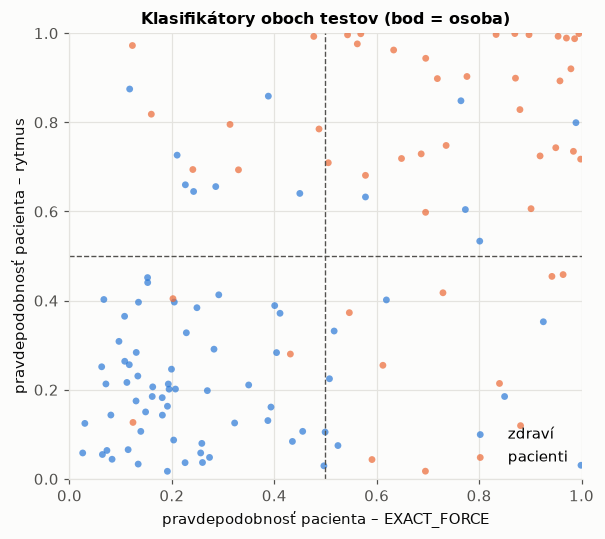

označený ako pacient testom,oba,len EXACT_FORCE,len RYTMUS,žiadny
group,,,,
pacienti,29,9,7,3
zdraví,5,7,7,57



**Záver 5:**
- Z 48 pacientov rozpoznajú **oba testy 29**, **len EXACT_FORCE 9**,
  **len rytmus 7** a **žiadny 3**. Aspoň jeden test teda zachytí 45 z 48
  pacientov, EXACT_FORCE sám 38 a rytmus sám 36.
- U zdravých sa testy mýlia **na rôznych ľuďoch**: falošný poplach v oboch testoch má len 5 z 76.
- Pravdepodobnosti oboch testov spolu u pacientov takmer nesúvisia (ρ = 0,21, p 0,151).
- **Testy sa dopĺňajú:** jednoduchý priemer oboch pravdepodobností dáva AUC **0,92**
  (EXACT_FORCE 0,85, rytmus 0,86); jeden spoločný
  model zo všetkých 20 parametrov dáva 0,88.


In [8]:
agree = C["classifier_agreement"]
fig, ax = plt.subplots(figsize=(5.6, 5))
for group in ["control", "patient"]:
    g = agree.loc[agree["group"] == group]
    ax.scatter(g["p_exact_force"], g["p_rhythm"], s=20, color=GROUP_COLORS[group], alpha=0.7, edgecolor="none",
               label=SK_GROUP[group])
ax.axvline(0.5, color=MUTED, lw=0.9, ls="--"); ax.axhline(0.5, color=MUTED, lw=0.9, ls="--")
ax.set_xlabel("pravdepodobnosť pacienta – EXACT_FORCE"); ax.set_ylabel("pravdepodobnosť pacienta – rytmus")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc="lower right")
ax.set_title("Klasifikátory oboch testov (bod = osoba)")
save(fig, "04_klasifikatory")

order = ["oba", "len EXACT_FORCE", "len RYTMUS", "žiadny"]
table = pd.crosstab(agree["group"].map(SK_GROUP), agree["flagged"]).reindex(columns=order, fill_value=0)
table.columns.name = "označený ako pacient testom"
display(table)
s = C["classifier_agreement_summary"].set_index("group")
both = COMB["classifier"]
lr_both = both.loc[(both["model"] == "logistická regresia") & (both["features"] == "EXACT_FORCE + rytmus")
                   & ~both["set"].str.contains("≥ 50"), "auc"].iloc[0]
pat = table.loc["pacienti"]; hea = table.loc["zdraví"]
display(Markdown(f"""
**Záver 5:**
- Z {int(pat.sum())} pacientov rozpoznajú **oba testy {pat['oba']}**, **len EXACT_FORCE {pat['len EXACT_FORCE']}**,
  **len rytmus {pat['len RYTMUS']}** a **žiadny {pat['žiadny']}**. Aspoň jeden test teda zachytí {int(pat.sum() - pat['žiadny'])} z {int(pat.sum())}
  pacientov, EXACT_FORCE sám {int(pat['oba'] + pat['len EXACT_FORCE'])} a rytmus sám {int(pat['oba'] + pat['len RYTMUS'])}.
- U zdravých sa testy mýlia **na rôznych ľuďoch**: falošný poplach v oboch testoch má len {hea['oba']} z {int(hea.sum())}.
- Pravdepodobnosti oboch testov spolu u pacientov takmer nesúvisia (ρ = {fmt(s.loc['patient', 'rho'])}, p {pval(s.loc['patient', 'p'])}).
- **Testy sa dopĺňajú:** jednoduchý priemer oboch pravdepodobností dáva AUC **{fmt(s.loc['všetci', 'auc_mean_probability'])}**
  (EXACT_FORCE {fmt(s.loc['všetci', 'auc_p_exact_force'])}, rytmus {fmt(s.loc['všetci', 'auc_p_rhythm'])}); jeden spoločný
  model zo všetkých 20 parametrov dáva {fmt(lr_both)}.
"""))

## 6. Opakovateľnosť: ktorý test dáva stabilnejšie výsledky?

35 pacientov bolo meraných **dvakrát** (medzi meraniami 3 – 14 dní). Pre každý parameter porovnáme hodnotu
z 1. a 2. merania:
- **ICC** (vnútrotriedny korelačný koeficient, zhoda dvoch meraní): 1 = rovnaké hodnoty, nad 0,75 dobrá, 0,5 – 0,75
  stredná, pod 0,5 slabá opakovateľnosť;
- **ρ** – Spearmanova korelácia 1. a 2. merania (zachová sa poradie pacientov?);
- **zmena** 2. – 1. meranie (Wilcoxonov test) – zlepšia sa pacienti pri druhom meraní?

Parameter, ktorý sa pri opakovaní veľmi mení, nemôže dobre oddeľovať skupiny ani sledovať priebeh liečby.
Zdraví boli merané len raz, preto je to len u pacientov.

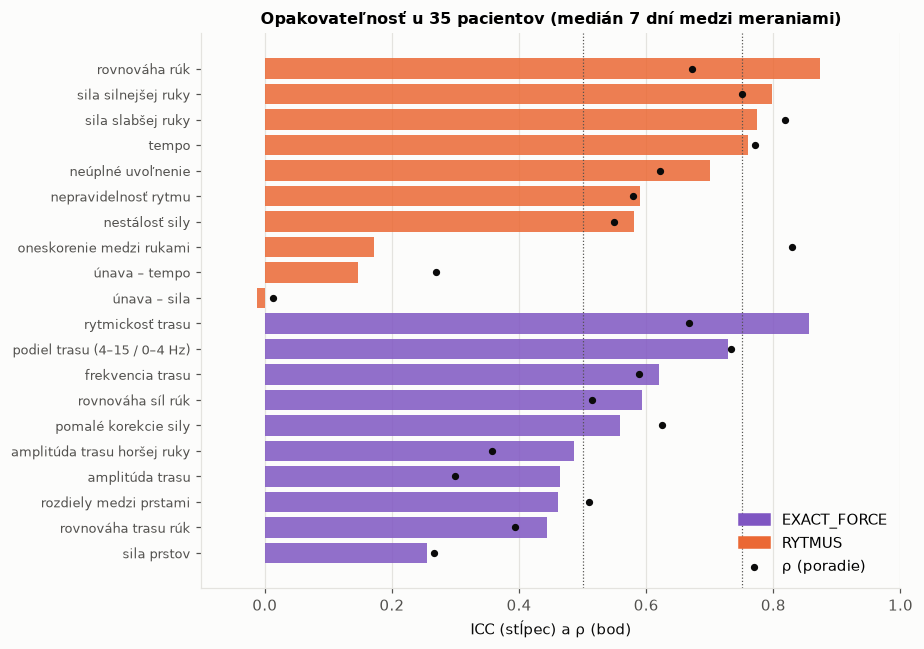

,test,parameter,ICC,ρ,medián 1. meranie,medián 2. meranie,p zmena,p zmena (Holm)
0,EXACT_FORCE,amplitúda trasu,"0,46","0,30","1,76e-05","1,49e-05","0,037","0,334"
1,EXACT_FORCE,amplitúda trasu horšej ruky,"0,49","0,36","2,32e-05","1,83e-05","0,033","0,327"
2,EXACT_FORCE,pomalé korekcie sily,"0,56","0,63","0,000206","0,000187","0,158","0,950"
3,EXACT_FORCE,podiel trasu (4–15 / 0–4 Hz),"0,73","0,73","0,104","0,109","0,716","1,000"
4,EXACT_FORCE,frekvencia trasu,"0,62","0,59","5,28","5,38","0,980","1,000"
5,EXACT_FORCE,rytmickosť trasu,"0,86","0,67","3,44","3,29","0,929","1,000"
6,EXACT_FORCE,sila prstov,"0,25","0,27","0,019","0,0191","0,273","1,000"
7,EXACT_FORCE,rovnováha síl rúk,"0,59","0,52","0,851","0,87","0,039","0,334"
8,EXACT_FORCE,rovnováha trasu rúk,"0,44","0,39","0,707","0,787","0,040","0,334"
9,EXACT_FORCE,rozdiely medzi prstami,"0,46","0,51","0,345","0,296","0,302","1,000"


In [9]:
rep = C["repeatability"]
gaps = C["visit_gaps"]
fig, ax = plt.subplots(figsize=(8.5, 6))
rep_sorted = rep.sort_values(["test", "icc"])
y = np.arange(len(rep_sorted))
ax.barh(y, rep_sorted["icc"], color=[TEST_COLORS[t] for t in rep_sorted["test"]], alpha=0.85)
ax.scatter(rep_sorted["rho"], y, color=TEXT, s=14, zorder=3, label="ρ (poradie)")
ax.set_yticks(y, [NAME[p] for p in rep_sorted["parameter"]], fontsize=8.5)
for x, label in [(0.5, "0,5"), (0.75, "0,75")]:
    ax.axvline(x, color=MUTED, lw=0.8, ls=":")
ax.set_xlim(-0.1, 1); ax.set_xlabel("ICC (stĺpec) a ρ (bod)"); ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in TEST_COLORS.values()] + [ax.collections[0]]
ax.legend(handles, [*TEST_COLORS, "ρ (poradie)"], loc="lower right")
ax.set_title(f"Opakovateľnosť u {int(rep['n_people'].max())} pacientov (medián {fmt(gaps['RYTMUS'].median(), 0)} dní medzi meraniami)")
save(fig, "05_opakovatelnost")

display(pd.DataFrame({
    "test": rep["test"], "parameter": rep["parameter"].map(NAME), "ICC": rep["icc"].map(fmt), "ρ": rep["rho"].map(fmt),
    "medián 1. meranie": rep["median_visit1"].map(lambda v: f"{v:.3g}".replace(".", ",")),
    "medián 2. meranie": rep["median_visit2"].map(lambda v: f"{v:.3g}".replace(".", ",")),
    "p zmena": rep["p_change"].map(pval), "p zmena (Holm)": rep["p_change_holm"].map(pval)}))

In [10]:
med = rep.groupby("test")["icc"].median()
good = rep.loc[rep["icc"] >= 0.75]
r = rep.set_index(["test", "parameter"])
display(Markdown(f"""
**Záver 6:**
- **Rytmický test je opakovateľnejší:** medián ICC rytmus {fmt(med['RYTMUS'])}, EXACT_FORCE {fmt(med['EXACT_FORCE'])}.
  Dobrú opakovateľnosť (ICC ≥ 0,75) majú: {names(good['parameter'])}.
- **Rovnováha rúk v rytme** má najvyššie ICC ({fmt(r.loc[('RYTMUS', 'balance'), 'icc'])}) – je to zároveň najstabilnejší rozdiel
  medzi zdravými a pacientmi. V EXACT_FORCE je rovnováha síl len stredne opakovateľná ({fmt(r.loc[('EXACT_FORCE', 'force_balance'), 'icc'])}).
- V EXACT_FORCE je najmenej stabilná **sila prstov** (ICC {fmt(r.loc[('EXACT_FORCE', 'mean_force'), 'icc'])}) a **amplitúda trasu**
  ({fmt(r.loc[('EXACT_FORCE', 'tremor_amplitude'), 'icc'])}) – tras sa medzi dňami mení viac ako rytmické parametre.
- **Únava** v rytme sa pri opakovaní nezachová vôbec (ICC ~0) – to vysvetľuje, prečo neoddeľuje skupiny: za 31 s sa
  únava neprejaví spoľahlivo.
- **Oneskorenie medzi rukami:** ICC je nízke ({fmt(r.loc[('RYTMUS', 'sync_lag_ms'), 'icc'])}), ale poradie pacientov sa zachová
  (ρ = {fmt(r.loc[('RYTMUS', 'sync_lag_ms'), 'rho'])}) – ICC pokazí jeden pacient, ktorý mal pri 1. meraní oneskorenie
  950 ms a pri 2. meraní 70 ms. ICC je citlivé na takéto extrémne hodnoty, Spearmanova korelácia nie.
- **Zmena pri 2. meraní:** tempo je o niečo vyššie (p {pval(r.loc[('RYTMUS', 'press_rate_hz'), 'p_change'])}, po Holmovej
  korekcii {pval(r.loc[('RYTMUS', 'press_rate_hz'), 'p_change_holm'])}); po korekcii sa žiadny parameter významne nezmenil.
  Malý efekt učenia (alebo liečby) medzi meraniami sa však vylúčiť nedá.
"""))


**Záver 6:**
- **Rytmický test je opakovateľnejší:** medián ICC rytmus 0,65, EXACT_FORCE 0,52.
  Dobrú opakovateľnosť (ICC ≥ 0,75) majú: rytmickosť trasu, tempo, sila silnejšej ruky, sila slabšej ruky, rovnováha rúk.
- **Rovnováha rúk v rytme** má najvyššie ICC (0,87) – je to zároveň najstabilnejší rozdiel
  medzi zdravými a pacientmi. V EXACT_FORCE je rovnováha síl len stredne opakovateľná (0,59).
- V EXACT_FORCE je najmenej stabilná **sila prstov** (ICC 0,25) a **amplitúda trasu**
  (0,46) – tras sa medzi dňami mení viac ako rytmické parametre.
- **Únava** v rytme sa pri opakovaní nezachová vôbec (ICC ~0) – to vysvetľuje, prečo neoddeľuje skupiny: za 31 s sa
  únava neprejaví spoľahlivo.
- **Oneskorenie medzi rukami:** ICC je nízke (0,17), ale poradie pacientov sa zachová
  (ρ = 0,83) – ICC pokazí jeden pacient, ktorý mal pri 1. meraní oneskorenie
  950 ms a pri 2. meraní 70 ms. ICC je citlivé na takéto extrémne hodnoty, Spearmanova korelácia nie.
- **Zmena pri 2. meraní:** tempo je o niečo vyššie (p 0,009, po Holmovej
  korekcii 0,088); po korekcii sa žiadny parameter významne nezmenil.
  Malý efekt učenia (alebo liečby) medzi meraniami sa však vylúčiť nedá.


## Celkové porovnanie

| | EXACT_FORCE | rytmus |
|---|---|---|
| čo test meria | tras a stabilitu držanej sily | rýchlosť, koordináciu a rovnováhu rúk |
| čo odlišuje pacientov pri rovnakom veku | pomalé korekcie sily, tras, rozdiely medzi prstami | tempo, rovnováha rúk, oneskorenie rúk |
| rovnováha rúk | rozdiel sa nepotvrdil | najstabilnejší rozdiel |
| klasifikátor (AUC) | ~0,85 | ~0,85 |
| opakovateľnosť | stredná | dobrá |

**Hlavné zistenia:**
1. Oba testy oddelia pacientov od zdravých **rovnako dobre**, ale **zachytávajú iné prejavy ochorenia** – EXACT_FORCE
   nestabilitu sily a tras, rytmus spomalenie a nerovnováhu rúk.
2. Testy **nemerajú to isté** (slabé korelácie) a ich klasifikátory sa **mýlia na rôznych ľuďoch**, preto sa
   **dopĺňajú** – spojenie oboch testov je lepšie ako ktorýkoľvek test sám.
3. **Slabšiu ruku ukáže lepšie rytmický test**; EXACT_FORCE ju pri pokojnom držaní sily väčšinou nezachytí.
4. **Rytmický test je opakovateľnejší** – vhodnejší na sledovanie pacienta v čase.

**Obmedzenia:**
- Zdraví a pacienti mali v oboch testoch **iné verzie úlohy** (iné `step_id`) a pacienti sú výrazne starší –
  porovnanie v rovnakých dekádach odstráni vek, nie verziu úlohy.
- Opakovateľnosť je len pre **35 pacientov**; zdraví boli merané raz. Medzi meraniami mohla prebiehať liečba.
- Výsledky nie sú overené na nezávislých dátach.